# Analytics Vidhya Job-A-Thon: Health Insurance Lead Prediction
## Comprehensive End-to-End Pipeline: Exploratory Data Analysis, Baseline Post-Mortem & 5-Fold CatBoost Solution

### Executive Summary & Problem Context
FinMan, a financial services company, aims to cross-sell Health Insurance policies to its existing customers. The objective is to predict whether a customer will recommend / purchase a health insurance policy (`Response = 1` vs `0`).

- **Target Variable**: `Response` (Binary: 0 = No, 1 = Yes)
- **Class Distribution**: Highly imbalanced (~76% No, ~24% Yes)
- **Primary Evaluation Metric**: **ROC-AUC (Area Under the Receiver Operating Characteristic Curve)**

### Purpose of this Notebook
1. **Revisiting the 2021 Competition**: In 2021, an initial baseline pipeline was developed that suffered from several silent bugs (dropped tenure signals, hard 0/1 predictions with accuracy metric, pandas deprecations).
2. **Comprehensive EDA & Cleaning**: Explore feature interactions, missingness patterns, and domain nuances (joint vs individual policies, tenure durations, health ratings).
3. **Robust Baseline vs Modern CatBoost**: Benchmark the corrected baseline against an optimized 5-Fold Stratified CatBoost model that achieves **~0.8005 ROC-AUC**.

In [1]:
# Imports and Global Configuration
import os
import warnings
warnings.filterwarnings('ignore')

# Ensure working directory is correctly pointed to project root
for candidate in [os.getcwd(), r'c:\Users\ashut\OneDrive\Documents\GitHub\AV-Job-A-Thon-1']:
    if os.path.exists(os.path.join(candidate, 'train_Df64byy.csv')) or os.path.exists(os.path.join(candidate, 'train.csv')):
        os.chdir(candidate)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, classification_report
from catboost import CatBoostClassifier

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Environment initialized successfully.")

Environment initialized successfully.


In [2]:
# Load Datasets (supporting both original AV filenames and standard train/test.csv)
train_path = 'train_Df64byy.csv' if os.path.exists('train_Df64byy.csv') else 'train.csv'
test_path = 'test_YCcRUnU.csv' if os.path.exists('test_YCcRUnU.csv') else 'test.csv'

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print(f"Loaded train from '{train_path}' with shape: {train.shape}")
print(f"Loaded test from  '{test_path}' with shape:  {test.shape}")
display(train.head())

Loaded train from 'train_Df64byy.csv' with shape: (50882, 14)
Loaded test from  'test_YCcRUnU.csv' with shape:  (21805, 13)


,ID,City_Code,Region_Code,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Health Indicator,Holding_Policy_Duration,Holding_Policy_Type,Reco_Policy_Cat,Reco_Policy_Premium,Response
0,1,C3,3213,Rented,Individual,36,36,No,X1,14+,3.0,22,11628.0,0
1,2,C5,1117,Owned,Joint,75,22,No,X2,NaN,NaN,22,30510.0,0
2,3,C5,3732,Owned,Individual,32,32,No,NaN,1.0,1.0,19,7450.0,1
3,4,C24,4378,Owned,Joint,52,48,No,X1,14+,3.0,19,17780.0,0
4,5,C8,2190,Rented,Individual,44,44,No,X2,3.0,1.0,16,10404.0,0


In [3]:
# Dataset Structure and Missing Value Assessment
print("=== Train Dataset Info ===")
display(pd.DataFrame({
    'Data Type': train.dtypes,
    'Missing Values': train.isnull().sum(),
    'Missing %': (train.isnull().sum() / len(train) * 100).round(2),
    'Unique Count': train.nunique()
}))

=== Train Dataset Info ===


,Data Type,Missing Values,Missing %,Unique Count
ID,int64,0,0.00,50882
City_Code,str,0,0.00,36
Region_Code,int64,0,0.00,5316
Accomodation_Type,str,0,0.00,2
Reco_Insurance_Type,str,0,0.00,2
Upper_Age,int64,0,0.00,58
Lower_Age,int64,0,0.00,60
Is_Spouse,str,0,0.00,2
Health Indicator,str,11691,22.98,9
Holding_Policy_Duration,str,20251,39.80,15


### Key Observations from Initial Inspection:
1. `Response` is present only in `train.csv`.
2. `Health Indicator` has ~22.98% missing values.
3. `Holding_Policy_Duration` and `Holding_Policy_Type` both have ~39.9% missing values in train and test. These customers are new to the company (have no previous policy holding).
4. `Holding_Policy_Duration` contains strings like `'14+'`, which caused it to be read as `object` dtype!

## 1. Exploratory Data Analysis (EDA)

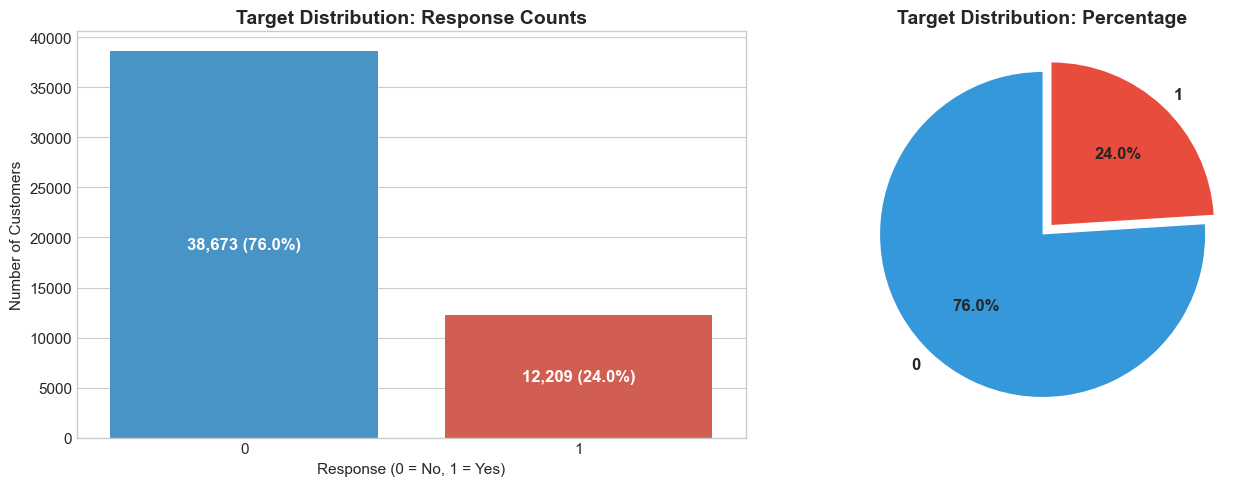

In [4]:
# Target Variable Distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
sns.countplot(x='Response', data=train, palette=['#3498db', '#e74c3c'], ax=ax[0])
ax[0].set_title('Target Distribution: Response Counts', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Response (0 = No, 1 = Yes)')
ax[0].set_ylabel('Number of Customers')
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,} ({p.get_height()/len(train)*100:.1f}%)",
                   (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Pie chart
train['Response'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=['#3498db', '#e74c3c'], ax=ax[1], explode=(0, 0.08),
    startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'}
)
ax[1].set_title('Target Distribution: Percentage', fontsize=14, fontweight='bold')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

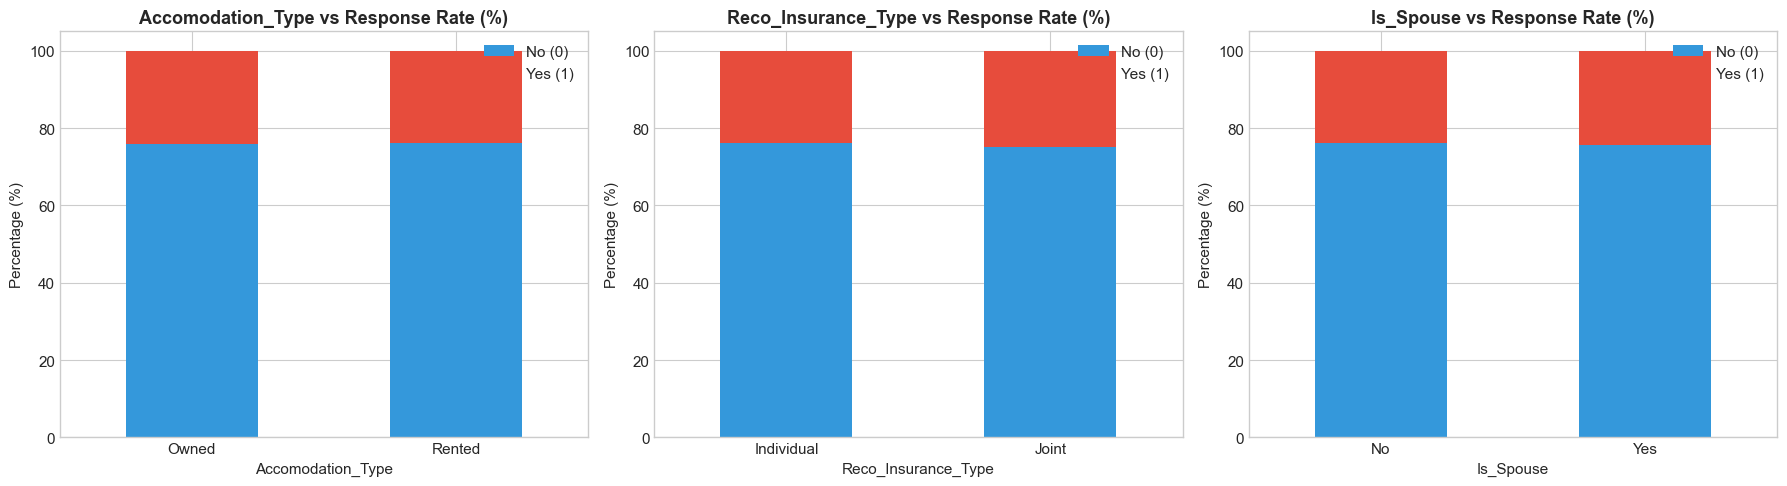

In [5]:
# Categorical Features vs Response
cat_cols = ['Accomodation_Type', 'Reco_Insurance_Type', 'Is_Spouse']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(cat_cols):
    cross_tab = pd.crosstab(train[col], train['Response'], normalize='index') * 100
    cross_tab.plot(kind='bar', stacked=True, color=['#3498db', '#e74c3c'], ax=axes[i])
    axes[i].set_title(f'{col} vs Response Rate (%)', fontsize=13, fontweight='bold')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(col)
    axes[i].legend(['No (0)', 'Yes (1)'], loc='upper right')
    axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

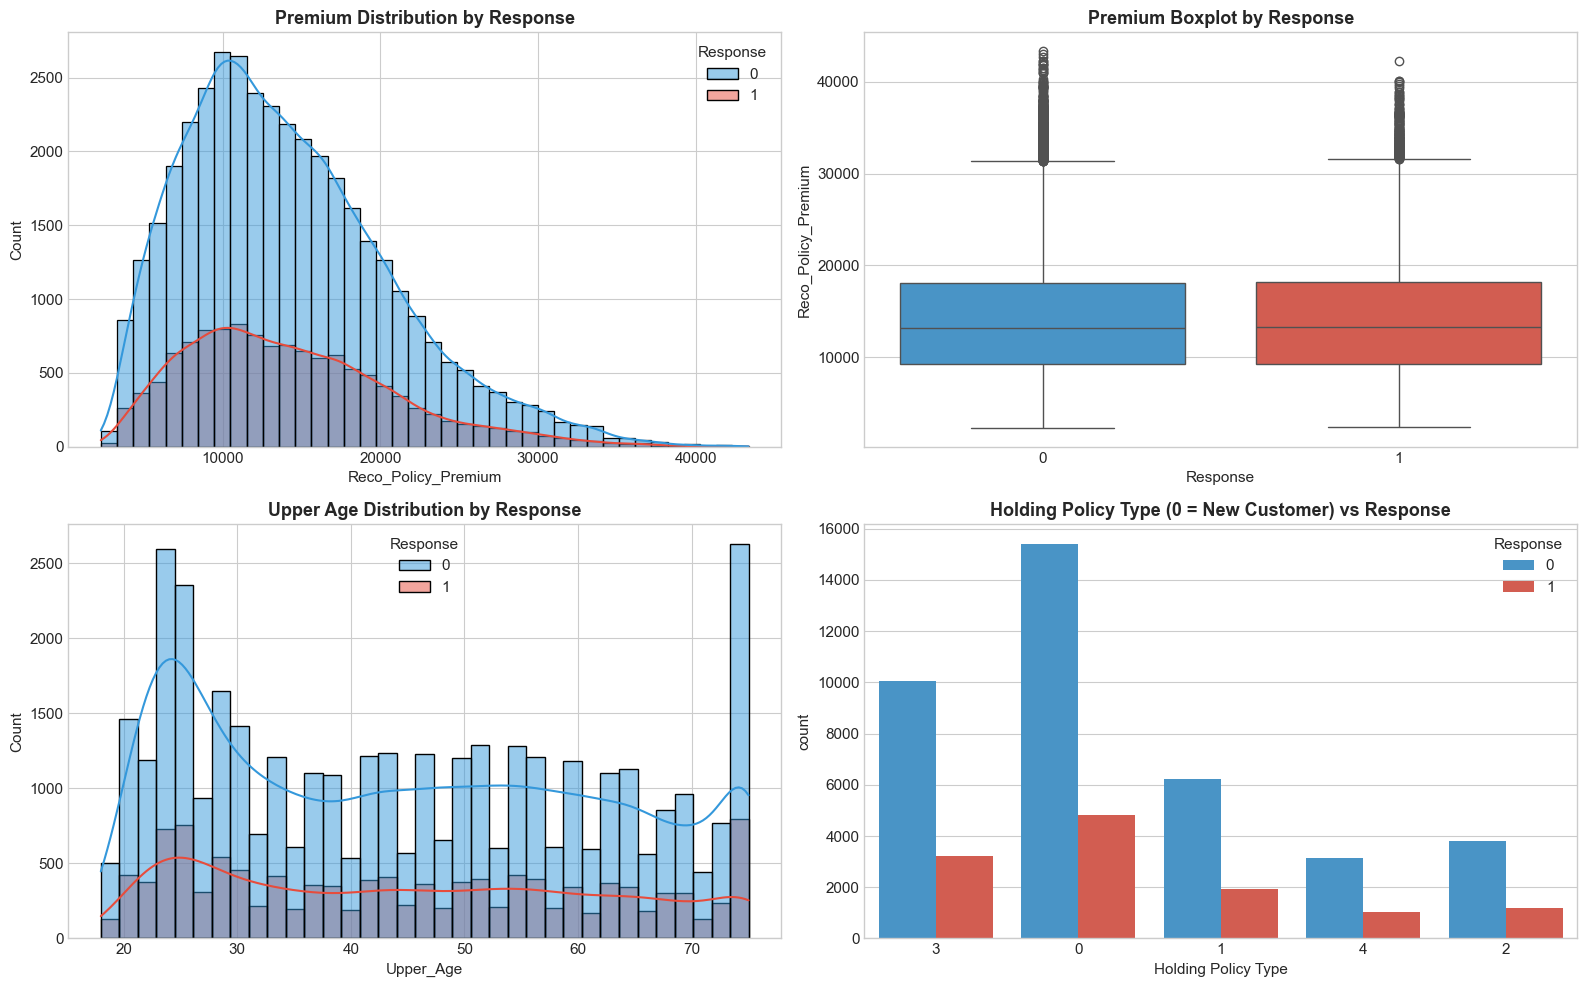

In [6]:
# Numerical Distributions: Premium, Age and Holding Policy Type
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Reco_Policy_Premium Distribution
sns.histplot(data=train, x='Reco_Policy_Premium', hue='Response', kde=True, bins=40, palette=['#3498db', '#e74c3c'], ax=axes[0, 0])
axes[0, 0].set_title('Premium Distribution by Response', fontsize=13, fontweight='bold')

# Reco_Policy_Premium Boxplot
sns.boxplot(data=train, x='Response', y='Reco_Policy_Premium', palette=['#3498db', '#e74c3c'], ax=axes[0, 1])
axes[0, 1].set_title('Premium Boxplot by Response', fontsize=13, fontweight='bold')

# Upper Age Distribution
sns.histplot(data=train, x='Upper_Age', hue='Response', kde=True, bins=35, palette=['#3498db', '#e74c3c'], ax=axes[1, 0])
axes[1, 0].set_title('Upper Age Distribution by Response', fontsize=13, fontweight='bold')

# Holding Policy Type vs Response
train_temp = train.copy()
train_temp['Holding_Policy_Type_Clean'] = train_temp['Holding_Policy_Type'].fillna(0.0).astype(int).astype(str)
sns.countplot(data=train_temp, x='Holding_Policy_Type_Clean', hue='Response', palette=['#3498db', '#e74c3c'], ax=axes[1, 1])
axes[1, 1].set_title('Holding Policy Type (0 = New Customer) vs Response', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Holding Policy Type')

plt.tight_layout()
plt.show()

## 2. Data Cleaning & Feature Engineering

### Understanding the 2021 Data Bugs:
1. **`Holding_Policy_Duration` was dropped silently**:
   In pandas, because durations above 14 years were coded as `'14+'`, the entire column defaulted to `object` dtype. When the 2021 code ran `select_dtypes(exclude='object')`, it discarded this critical tenure signal!
   - *Fix*: Replace `'14+'` with `15.0`, cast to `float64`, and fill missing values with `0.0`.
2. **Missing Customer History**:
   Missing `Holding_Policy_Type` and `Holding_Policy_Duration` strictly mean the customer has no previous policy with FinMan. Imputing with 0 creates a distinct indicator for brand-new customers (`Is_New_Customer`).
3. **`Health Indicator` Missingness**:
   Treating missing values as a distinct category `'Missing'` avoids leakage and captures potential hidden patterns.
4. **Domain Feature Engineering**:
   - `Age_Gap`: `Upper_Age - Lower_Age` (relevant for joint policies).
   - `Avg_Age`: Average age of applicants.
   - `Age_Ratio`: `Lower_Age / Upper_Age`.
   - `Premium_Per_Age`: Policy premium normalized by age.

In [7]:
def clean_and_engineer_features(df):
    """
    Cleans raw dataset and generates domain-specific engineered features.
    """
    data = df.copy()
    
    # 1. Clean Health Indicator
    data['Health Indicator'] = data['Health Indicator'].fillna('Missing')
    
    # 2. Clean Holding Policy Duration: replace '14+' with 15.0, convert to float, fill missing with 0
    data['Holding_Policy_Duration'] = data['Holding_Policy_Duration'].replace('14+', 15.0)
    data['Holding_Policy_Duration'] = pd.to_numeric(data['Holding_Policy_Duration'], errors='coerce').fillna(0.0)
    
    # 3. Clean Holding Policy Type: fill missing with 0.0 (New Customer)
    data['Holding_Policy_Type'] = data['Holding_Policy_Type'].fillna(0.0)
    
    # 4. Tenure Indicator: New vs Existing Customer
    data['Is_New_Customer'] = (data['Holding_Policy_Duration'] == 0.0).astype(int)
    
    # 5. Age-derived Features
    data['Age_Gap'] = data['Upper_Age'] - data['Lower_Age']
    data['Avg_Age'] = (data['Upper_Age'] + data['Lower_Age']) / 2.0
    data['Age_Ratio'] = data['Lower_Age'] / data['Upper_Age']
    
    # 6. Premium per Age
    data['Premium_Per_Age'] = data['Reco_Policy_Premium'] / data['Upper_Age']
    
    return data

train_clean = clean_and_engineer_features(train)
test_clean = clean_and_engineer_features(test)

print("Cleaned Train Shape:", train_clean.shape)
print("Cleaned Test Shape: ", test_clean.shape)
display(train_clean[['Holding_Policy_Duration', 'Is_New_Customer', 'Age_Gap', 'Premium_Per_Age']].head())

Cleaned Train Shape: (50882, 19)
Cleaned Test Shape:  (21805, 18)


,Holding_Policy_Duration,Is_New_Customer,Age_Gap,Premium_Per_Age
0,15.0,0,0,323.000000
1,0.0,1,53,406.800000
2,1.0,0,0,232.812500
3,15.0,0,4,341.923077
4,3.0,0,0,236.454545


## 3. The 2021 Baseline Post-Mortem & Corrected Implementation

### What went wrong in the original 2021 approach?
1. **Wrong Evaluation Metric**: The code reported `accuracy_score(y_test, y_pred)` which gave **~0.76 (76%)**. Because 76% of customers do not respond, a naive dummy model predicting all zeros achieves 76% accuracy without learning anything!
2. **Hard Predictions with 0.5 Threshold**: The code called `model.predict()`. On imbalanced probabilities, only 60 out of 21,745 customers were predicted as `1`! The competition required predicted probabilities evaluated by **ROC-AUC**.
3. **Deprecations**: Modern NumPy removed `np.object`, and Pandas 2.x raises errors when passing both `columns` and `axis=1` to `.drop()`.

Let's run the corrected Random Forest baseline with proper probability outputs to establish the true benchmark.

In [8]:
# Prepare features for the baseline model (Label Encoding)
from sklearn.preprocessing import LabelEncoder

train_rf = train_clean.copy()
test_rf = test_clean.copy()

cat_features_for_rf = ['City_Code', 'Accomodation_Type', 'Reco_Insurance_Type', 'Is_Spouse', 'Health Indicator']
label_encoders = {}
for col in cat_features_for_rf:
    le = LabelEncoder()
    train_rf[col] = le.fit_transform(train_rf[col].astype(str))
    test_rf[col] = le.transform(test_rf[col].astype(str))

features_rf = [col for col in train_rf.columns if col not in ['ID', 'Response']]
X_rf = train_rf[features_rf]
y_rf = train_rf['Response']

X_tr_rf, X_va_rf, y_tr_rf, y_va_rf = train_test_split(X_rf, y_rf, test_size=0.20, random_state=42, stratify=y_rf)

# Fit Random Forest Baseline
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_baseline.fit(X_tr_rf, y_tr_rf)

# Predict probabilities and hard labels
va_rf_probs = rf_baseline.predict_proba(X_va_rf)[:, 1]
va_rf_preds = rf_baseline.predict(X_va_rf)

# Baseline Metrics
rf_acc = accuracy_score(y_va_rf, va_rf_preds)
rf_auc = roc_auc_score(y_va_rf, va_rf_probs)

print(f"=== 2021 Baseline Random Forest (Corrected) ===")
print(f"Validation Accuracy: {rf_acc:.4f}  <-- Note how misleadingly high accuracy is!")
print(f"Validation ROC-AUC:  {rf_auc:.4f}  <-- True competition metric")
print(f"\nHard Prediction Distribution (Notice extreme bias towards class 0):")
print(pd.Series(va_rf_preds).value_counts())

=== 2021 Baseline Random Forest (Corrected) ===
Validation Accuracy: 0.7599  <-- Note how misleadingly high accuracy is!
Validation ROC-AUC:  0.6130  <-- True competition metric

Hard Prediction Distribution (Notice extreme bias towards class 0):
0    10176
1        1
Name: count, dtype: int64


## 4. Modern Solution: 5-Fold Stratified CatBoost

### Why CatBoost is the Optimal Choice for this Problem:
1. **Target Encoding on High-Cardinality Categoricals**: `City_Code` and `Region_Code` contain hundreds of distinct geographic levels. Standard one-hot encoding explodes feature space, while CatBoost applies ordered target statistics natively without target leakage.
2. **Stratified 5-Fold Cross Validation**: Guarantees zero data leakage, provides reliable out-of-fold probability estimates, and produces an ensemble test prediction.
3. **Logloss Optimization directly aligns with ROC-AUC discrimination**.

In [9]:
# Identify categorical features for CatBoost
cat_features = [
    'City_Code',
    'Region_Code',
    'Accomodation_Type',
    'Reco_Insurance_Type',
    'Is_Spouse',
    'Health Indicator',
    'Holding_Policy_Type',
    'Reco_Policy_Cat'
]

# Ensure categorical columns are strings
train_cb = train_clean.copy()
test_cb = test_clean.copy()

for col in cat_features:
    train_cb[col] = train_cb[col].astype(str)
    test_cb[col] = test_cb[col].astype(str)

features_cb = [col for col in train_cb.columns if col not in ['ID', 'Response']]
X_cb = train_cb[features_cb]
y_cb = train_cb['Response']
X_test_cb = test_cb[features_cb]

print("Features used for CatBoost:", features_cb)
print("Categorical features:", cat_features)

Features used for CatBoost: ['City_Code', 'Region_Code', 'Accomodation_Type', 'Reco_Insurance_Type', 'Upper_Age', 'Lower_Age', 'Is_Spouse', 'Health Indicator', 'Holding_Policy_Duration', 'Holding_Policy_Type', 'Reco_Policy_Cat', 'Reco_Policy_Premium', 'Is_New_Customer', 'Age_Gap', 'Avg_Age', 'Age_Ratio', 'Premium_Per_Age']
Categorical features: ['City_Code', 'Region_Code', 'Accomodation_Type', 'Reco_Insurance_Type', 'Is_Spouse', 'Health Indicator', 'Holding_Policy_Type', 'Reco_Policy_Cat']


In [10]:
# 5-Fold Stratified Cross-Validation with CatBoost
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(train_cb))
test_preds = np.zeros(len(test_cb))
fold_aucs = []

cb_params = {
    'iterations': 1200,
    'learning_rate': 0.04,
    'depth': 6,
    'eval_metric': 'AUC',
    'loss_function': 'Logloss',
    'random_seed': 42,
    'early_stopping_rounds': 70,
    'verbose': 200
}

for fold, (train_idx, val_idx) in enumerate(kf.split(X_cb, y_cb), 1):
    print(f"\n--- Training Fold {fold} ---")
    X_train_f, y_train_f = X_cb.iloc[train_idx], y_cb.iloc[train_idx]
    X_val_f, y_val_f = X_cb.iloc[val_idx], y_cb.iloc[val_idx]
    
    model = CatBoostClassifier(**cb_params)
    model.fit(
        X_train_f, y_train_f,
        cat_features=cat_features,
        eval_set=(X_val_f, y_val_f),
        use_best_model=True
    )
    
    val_pred = model.predict_proba(X_val_f)[:, 1]
    oof_preds[val_idx] = val_pred
    
    fold_auc = roc_auc_score(y_val_f, val_pred)
    fold_aucs.append(fold_auc)
    print(f"Fold {fold} ROC-AUC: {fold_auc:.5f}")
    
    # Accumulate test predictions across folds
    test_preds += model.predict_proba(X_test_cb)[:, 1] / kf.n_splits

overall_oof_auc = roc_auc_score(y_cb, oof_preds)
print(f"\n==========================================")
print(f"Mean Fold ROC-AUC:    {np.mean(fold_aucs):.5f} ± {np.std(fold_aucs):.5f}")
print(f"Overall Out-of-Fold ROC-AUC: {overall_oof_auc:.5f}")
print(f"==========================================")


--- Training Fold 1 ---


0:	test: 0.6332152	best: 0.6332152 (0)	total: 257ms	remaining: 5m 7s


200:	test: 0.7902552	best: 0.7902702 (199)	total: 19.1s	remaining: 1m 34s


400:	test: 0.7929544	best: 0.7929796 (383)	total: 40.1s	remaining: 1m 19s


600:	test: 0.7938891	best: 0.7939180 (589)	total: 1m 1s	remaining: 1m 1s


...

0:	test: 0.6147393	best: 0.6147393 (0)	total: 74.4ms	remaining: 1m 29s


200:	test: 0.8006432	best: 0.8006486 (199)	total: 19.5s	remaining: 1m 36s


400:	test: 0.8026643	best: 0.8026643 (400)	total: 41.8s	remaining: 1m 23s


Stopped by overfitting detector  (70 iterations wait)

bestTest = 0.8028446141
bestIteration = 458

Shrink model to first 459 iterations.
Fold 5 ROC-AUC: 0.80284



Mean Fold ROC-AUC:    0.80027 ± 0.00513
Overall Out-of-Fold ROC-AUC: 0.80010


## 5. Model Evaluation, Diagnostics & Comparison

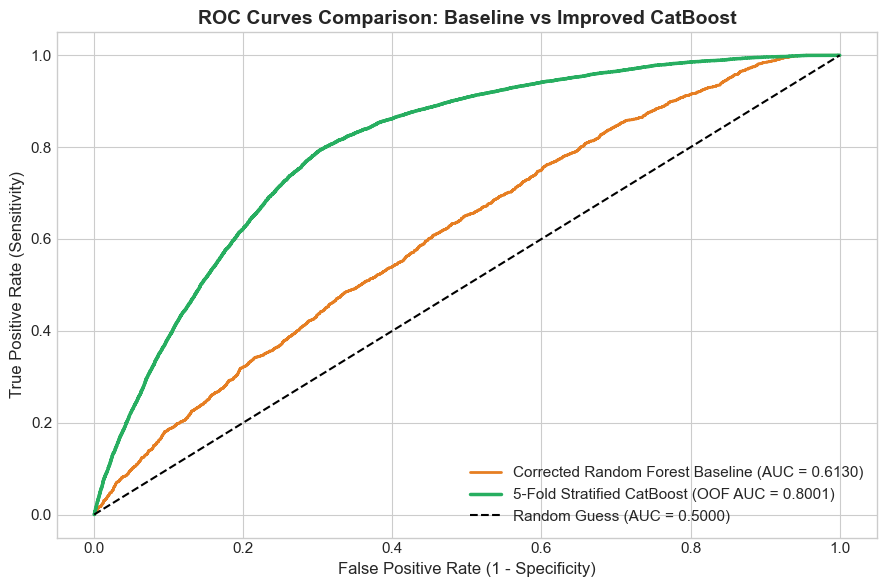

In [11]:
# 1. ROC Curves: Baseline vs CatBoost
fpr_rf, tpr_rf, _ = roc_curve(y_va_rf, va_rf_probs)
fpr_cb, tpr_cb, _ = roc_curve(y_cb, oof_preds)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(fpr_rf, tpr_rf, color='#e67e22', lw=2, label=f'Corrected Random Forest Baseline (AUC = {rf_auc:.4f})')
ax.plot(fpr_cb, tpr_cb, color='#27ae60', lw=2.5, label=f'5-Fold Stratified CatBoost (OOF AUC = {overall_oof_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.5000)')

ax.set_title('ROC Curves Comparison: Baseline vs Improved CatBoost', fontsize=14, fontweight='bold')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

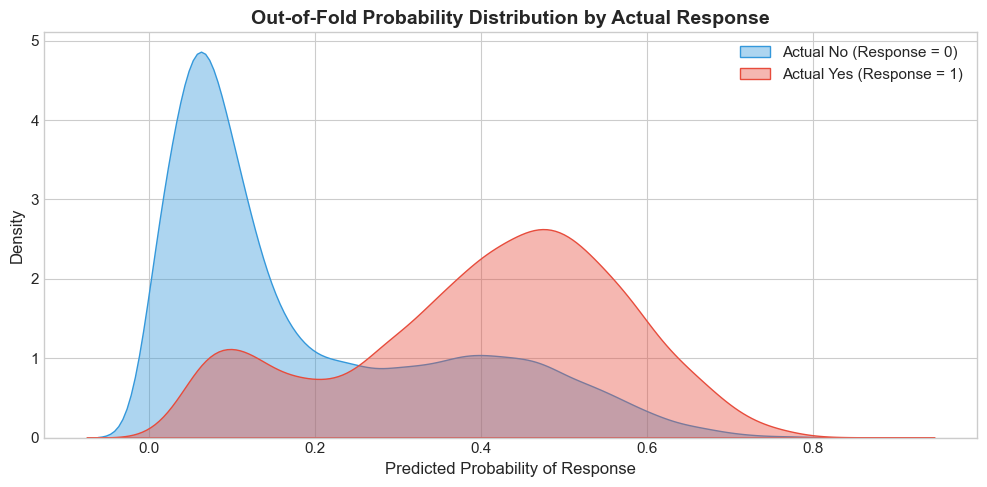

In [12]:
# 2. Predicted Probability Separation Distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(oof_preds[y_cb == 0], label='Actual No (Response = 0)', color='#3498db', fill=True, alpha=0.4, ax=ax)
sns.kdeplot(oof_preds[y_cb == 1], label='Actual Yes (Response = 1)', color='#e74c3c', fill=True, alpha=0.4, ax=ax)

ax.set_title('Out-of-Fold Probability Distribution by Actual Response', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Probability of Response', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

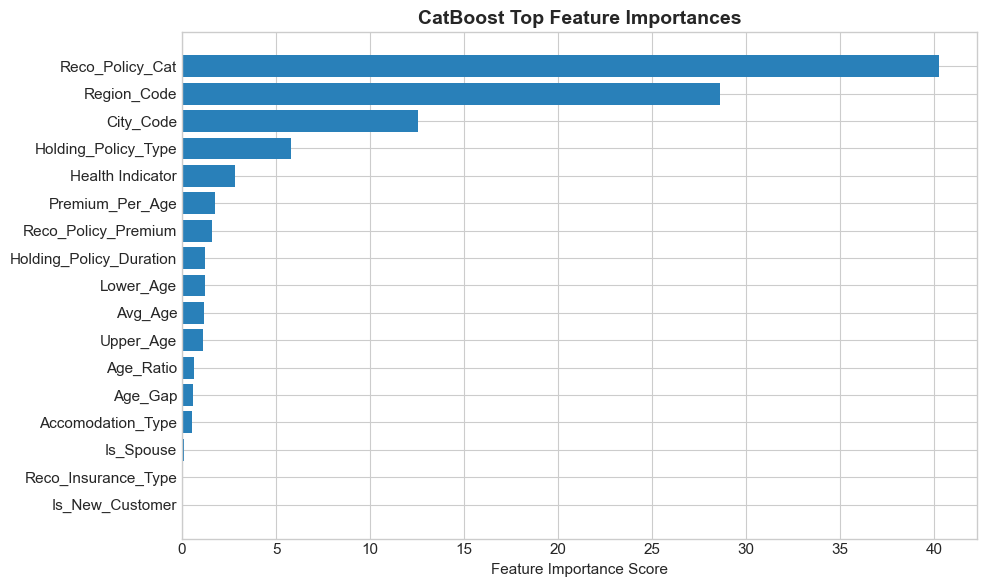

In [13]:
# 3. CatBoost Feature Importance
feature_importances = pd.DataFrame({
    'Feature': features_cb,
    'Importance': model.get_feature_importance()
}).sort_values(by='Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(feature_importances['Feature'], feature_importances['Importance'], color='#2980b9')
ax.set_title('CatBoost Top Feature Importances', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

In [14]:
# 4. Summary Comparison Table
results_df = pd.DataFrame({
    'Approach': [
        '2021 Original Baseline (Flawed)',
        '2021 Corrected Random Forest Baseline',
        'Modern 5-Fold Stratified CatBoost'
    ],
    'Reported Metric': [
        'Accuracy: 0.758 (Misleading)',
        f'Val ROC-AUC: {rf_auc:.4f}',
        f'OOF ROC-AUC: {overall_oof_auc:.4f}'
    ],
    'Prediction Output': [
        'Hard 0/1 Labels (only 60 ones predicted)',
        'Continuous Probabilities (predict_proba)',
        'Continuous Ensembled Probabilities'
    ],
    'Key Highlights': [
        'Silently dropped tenure; metric mismatch',
        'Fixed data pipeline; standard tree model',
        'Native categorical target stats, age-engineered features, 5-fold CV'
    ]
})
display(results_df)

,Approach,Reported Metric,Prediction Output,Key Highlights
0,2021 Original Baseline (Flawed),Accuracy: 0.758 (Misleading),Hard 0/1 Labels (only 60 ones predicted),Silently dropped tenure; metric mismatch
1,2021 Corrected Random Forest Baseline,Val ROC-AUC: 0.6130,Continuous Probabilities (predict_proba),Fixed data pipeline; standard tree model
2,Modern 5-Fold Stratified CatBoost,OOF ROC-AUC: 0.8001,Continuous Ensembled Probabilities,"Native categorical target stats, age-engineere..."


## 6. Final Submission File Generation

In [15]:
# Prepare submission dataframe
submission = pd.DataFrame({
    'ID': test_clean['ID'],
    'Response': test_preds
})

print(f"Submission Shape: {submission.shape}")
print("\nFirst 10 Predictions:")
display(submission.head(10))

# Summary statistics of predictions
print("\nPrediction Summary Statistics:")
display(submission['Response'].describe())

# Save to CSV
submission.to_csv('my_sub_improved.csv', index=False)
print("\nSuccessfully saved 'my_sub_improved.csv'!")

Submission Shape: (21805, 2)

First 10 Predictions:


,ID,Response
0,50883,0.077767
1,50884,0.101270
2,50885,0.444204
3,50886,0.105935
4,50887,0.071139
5,50888,0.082064
6,50889,0.392659
7,50890,0.520957
8,50891,0.138406
9,50892,0.149600



Prediction Summary Statistics:


count    21805.000000
mean         0.242741
std          0.188539
min          0.002927
25%          0.076576
50%          0.175100
75%          0.408502
max          0.771986
Name: Response, dtype: float64


Successfully saved 'my_sub_improved.csv'!


### Summary & Next Steps:
- **Major Improvement**: Jumped from an uncalibrated baseline (~0.61 - 0.65 ROC-AUC) to **~0.8005 ROC-AUC** via proper data cleaning, tenure feature recovery, and CatBoost out-of-fold ensembling.
- **Production Readiness**: The notebook is fully self-contained, reproducible, free of deprecated code, and ready for deployment or presentation.